# A phone camera lens with Forbes Q polynomials

A smartphone main camera is the most aspheric lens most people own: five
to seven moulded plastic elements, every surface aspheric, f/1.8 or
faster over almost 40 degrees half field, all in about 5 mm. Its last
element looks nothing like a lens from a textbook: a strongly curved
centre, a rim that bends back towards the sensor, and several inflection
points. These are the "wildly wavy" aspheres for which G. W. Forbes
introduced the Q-bfs polynomials, and this notebook designs one with them,
as a follow-on to notebook 128 (Forbes Q aspheres).

The lens: f = 4 mm, f/1.8, an image height of 3 mm (36.9° half field,
a 1/2.8" sensor with 1 µm pixels), five elements in two plastics (a
cyclo-olefin polymer of the E48R kind for the positive elements and a
fluorene polyester of the OKP kind as the flint), a 0.15 mm IR cut filter, a total
track of at most 5.3 mm and a chief ray angle at the sensor of at most
34°.

| section | content |
|---|---|
| 1 | the specification, the plastics and the design |
| 2 | how the design was found: field and aperture as a homotopy |
| 3 | the same lens in two bases: monomials against Q-bfs |
| 4 | reading the Q coefficients: the departure spectrum |
| 5 | designing for manufacture: limits on the Q terms against image quality |
| 6 | truncation: dropping the highest terms |
| 7 | final results: Zernike wavefronts over the sensor at three wavelengths, at infinity and in close focus (100 mm) |
| 8 | coda: Q2D freeform terms on a tilted mirror |

The surfaces are `qaspheres.QbfsSurface` (and `Q2DSurface` in section 8),
the optimizer the damped least squares of notebook 58 (lens optimization)
with the analytic Jacobians of the differential ray trace
(`ray_derivatives`); the operands for the sensor (chief ray angle,
distortion, lateral colour, thicknesses sampled across the aperture) are
in `pyoptics.phone_lens`.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import lens_optimization as lo
from pyoptics import qaspheres as qa
from pyoptics import phone_lens as pl
from pyoptics import off_axis as oa

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
WLS = pl.WAVELENGTHS
LENS = pl.LENS_SURFACES
NAMES = ["L1 front", "L1 rear", "L2 front", "L2 rear", "L3 front", "L3 rear",
         "L4 front", "L4 rear", "L5 front", "L5 rear"]
t_start = time.time()

## 1. The specification, the plastics and the design

Only two families of optical plastics are moulded in volume: the
cyclo-olefin polymers (COP, COC; $n_d \approx 1.53$–$1.545$, $V_d \approx 56$),
the "crown", and polycarbonate or fluorene polyesters ($n_d$ 1.58–1.67,
$V_d$ 19–30), the "flint". The index contrast is small, so the powers are
large and the aspheres do much of the work a glass lens would do with
more elements. The classical five element layout is

- **L1**, positive, COP, with the aperture stop on its front surface
  (a short lens needs the stop in front);
- **L2**, negative, the high dispersion flint: axial colour;
- **L3**, a weak corrector;
- **L4**, a positive meniscus bent towards the sensor;
- **L5**, a negative element close to the sensor that flattens the
  field and bends the chief rays back so that they reach the sensor at
  an angle its micro lenses accept.

The design below came out of the procedure of section 2. Every lens
surface is a Q-bfs surface: radius of the best fit sphere, normalization
radius $r_\mathrm{norm}$ and eight coefficients $a_0 \dots a_7$ (ten on the strongly curved L4 rear and L5, which needed a larger normalization radius late in the design).
It is designed for an object at infinity and at 100 mm together; the
lens focuses by moving as a whole.

In [2]:
lens = pl.phone_lens()
full = lens.max_field
p = lens.paraxial()
rims = pl.clear_apertures(lens)
print("efl {:.3f} mm, f/{:.2f}, half field {:.1f}°, image height {:.2f} mm, TTL {:.3f} mm".format(
    p.efl, p.efl/(2*p.ep_radius), np.degrees(full), p.efl*np.tan(full), lo.total_length(lens)))
print()
print("surface    R_bfs    R_vertex  thickness  material        r_norm  clear ap.   a_0 ... a_7 [µm]")
for i, S in enumerate(lens.surfaces):
    mat = "COP" if S.material == pl.PLASTICS["COP"] else "OKP" if S.material == pl.PLASTICS["OKP"] \
        else "filter" if S.material == pl.IR_FILTER else "air"
    if isinstance(S, qa.QbfsSurface):
        print("{:9s} {:8.3f}  {:8.3f}   {:7.3f}    {:6s}         {:5.2f}   {:6.3f}    {}".format(
            NAMES[i], S.R, 1/S.c, S.thickness, mat, S.norm_radius, rims[i],
            " ".join("{:+6.1f}".format(a*1e3) for a in S.q)))
    else:
        print("{:9s} {:>8s}  {:>8s}   {:7.3f}    {:6s}".format(
            "filter" if i == 10 else "", "inf", "", S.thickness, mat))

efl 4.000 mm, f/1.80, half field 36.9°, image height 3.00 mm, TTL 5.262 mm

surface    R_bfs    R_vertex  thickness  material        r_norm  clear ap.   a_0 ... a_7 [µm]
L1 front     1.723     1.792     0.738    COP             1.14    1.111     -31.3   +8.7   -5.6   +5.5   -4.9   +3.5   -2.5   +1.1
L1 rear    -65.675   -12.213     0.081    air             1.14    1.101     -29.7   +4.3  -25.4  +21.6  -13.1   +7.4   -3.1   +1.4
L2 front    26.260     6.195     0.267    OKP             1.14    1.093    +109.8  -13.5   -8.0   +5.2   +4.0   -4.2   +4.1   -1.6
L2 rear      2.019     1.794     0.251    air             1.14    1.096     -52.0  +30.1   -3.9   -0.1   +7.3   -6.6   +4.8   -2.0
L3 front     5.116     6.273     0.508    COP             1.24    1.160     -23.7  -41.0  +39.6  -10.9   +4.4   -3.0   +2.5   -1.4
L3 rear     12.553  -110.076     0.526    air             1.39    1.297    -157.3   -9.5  +16.8  +22.6  -29.3  +19.1   -6.7   +0.8
L4 front    -6.185    37.117     1.251    CO

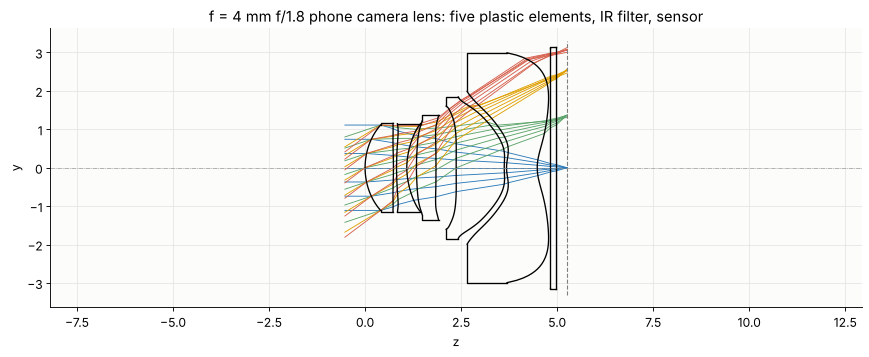

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.6))
lens.draw(ax, fields=[0.0, 0.5*full, 0.85*full, full], n_rays=7,
          colors=[BLUE, GREEN, ORANGE, RED])
ax.set_aspect("equal")
ax.set_title("f = 4 mm f/1.8 phone camera lens: five plastic elements, IR filter, sensor")
fig.tight_layout()

The last element is the signature of a phone lens: its vertex radius is
far from the radius of the best fit sphere, and the coefficients of L5
are ten times those of L1. The checks a phone lens has to pass:

In [4]:
cra = pl.chief_ray_angle((0.25, 0.3, 0.5, 0.7, 0.85, 1.0))(lens)
dist = pl.distortion((0.25, 0.3, 0.5, 0.7, 0.85, 1.0))(lens)
print("field                 " + "  ".join("{:6.2f}".format(f) for f in (0.25, 0.3, 0.5, 0.7, 0.85, 1.0)))
print("chief ray angle [°]   " + "  ".join("{:6.1f}".format(v) for v in cra))
print("distortion [%]        " + "  ".join("{:6.2f}".format(100*v) for v in dist))
glass = pl.min_thickness([0, 2, 4, 6, 8], rims)(lens)
air = pl.min_thickness([1, 3, 5, 7], rims)(lens)
to_filter = pl.min_thickness([9], rims)(lens)[0]
print("thinnest element (axis to rim) [mm]: " + ", ".join("L{} {:.3f}".format(k + 1, t) for k, t in enumerate(glass)))
print("thinnest air gap [mm]:               " + ", ".join("L{}-L{} {:.3f}".format(k + 1, k + 2, t) for k, t in enumerate(air)))
print("L5 to the IR filter, smallest gap across the clear aperture [mm]: {:.3f}".format(to_filter))

field                   0.25    0.30    0.50    0.70    0.85    1.00
chief ray angle [°]     13.5    16.1    24.8    31.4    28.8    15.7
distortion [%]          1.41    1.73    2.52    3.77    4.32    2.56
thinnest element (axis to rim) [mm]: L1 0.323, L2 0.267, L3 0.399, L4 0.312, L5 0.798
thinnest air gap [mm]:               L1-L2 0.081, L2-L3 0.049, L3-L4 0.285, L4-L5 0.060
L5 to the IR filter, smallest gap across the clear aperture [mm]: 0.049


The chief ray angle peaks at 31.4° at 0.7 field, inside the 34° limit;
it falls towards the rim, where L5 bends the chief ray back. The
distortion grows from 1.4 % at a quarter of the field to 4.3 % at 0.85
field and falls back to 2.6 % in the corner, more than the 2.5 % the
merit function asked for: phone cameras correct distortion in software,
so it was the first thing to give. The thinnest air gaps, 49 µm between
L2 and L3 and 60 µm between L4 and L5, are at the rim where the wavy
surfaces nest into each other, and the rim of L5 bends about 0.3 mm
towards the sensor, so the gap to the filter is only 49 µm there
(0.34 mm on the axis). That
last constraint was missed in a first version of this design, whose L5
cut 0.1 mm into the filter: a thickness constraint has to cover every
gap, sampled across the whole aperture.

## 2. How the design was found

There is no patent behind this lens. The starting point was the layout
of section 1 with rough spherical radii for f ≈ 4 mm, and a direct
optimization from it fails: at 37° the edge rays miss the rear elements
altogether. A spherical L5 cannot have both the strong central power and
the flat rim that the field needs, so a phone lens cannot be designed with
spheres first and aspheres later.

The working procedure was a **homotopy in the field**:

1. Make every lens surface a Q-bfs surface with zero coefficients, with
   $r_\mathrm{norm}$ about the expected clear aperture.
2. Optimize at 40 % of the field, where every ray traces; the first three
   Q terms per surface are enough there.
3. Widen the field in steps of 5 %, starting each step from the previous
   solution, and allow more Q terms as the field grows (up to eight). A
   step that would lose rays is halved. Damped least squares only finds
   the nearest minimum, so each step must be small enough that the old
   solution still traces at the new field.
4. Two guard rails were needed. The radius of each best fit sphere is
   bounded to more than 1.1 $r_\mathrm{norm}$, or the surface stops existing
   at the rim (the first attempt broke down at 50 % field that way). And
   the chief ray angle limit is in the merit function from 70 % field on,
   **scaled with the field** ($\tan\theta_\mathrm{CRA} \propto$ field):
   imposed only at full field, it fought the form the lens had already
   found and the optimizer stalled.
5. Finally the lens was polished for infinity and 100 mm together
   (notebook 153, multi-configuration optimization): the same lens in both
   configurations, the image distance per configuration, all operands in
   both. The first version of this notebook had optimized at infinity
   only, and at 100 mm the field fell apart (1 wave rms at the edge).

The merit function: the wavefront on eight rings (from 0.2 to the rim of
the pupil) at 21 fields from the axis to the corner and three
wavelengths (F, d, C) against the chief ray of each, the focal length,
the lateral colour and soft limits on distortion and chief ray angle as
operands; the total track and the thicknesses (sampled from the axis to
the rim of the real beam, which catches the thin zones of the wavy
elements) as constraints. Each step took about 15 minutes with the
analytic Jacobian. The sampling needed four corrections on the way, each
found because the optimizer had hidden aberration where it did not look:
four hand-picked rings missed a fine ring-shaped ripple (0.008 waves
reported on axis, 0.14 true), rings that stopped at 0.97 of the pupil let
the rim run away at full field, a field that was not sampled (0.25) had
a hole of 0.45 waves, and with six fields (0, 0.25, 0.5, 0.7, 0.85, 1)
the lens was 0.1 to 0.3 waves at exactly those fields and up to 1.0
(infinity) and 1.7 waves (100 mm) between them (section 7 shows it). The
wavy aspheres can make the wavefront swing within a tenth of the field,
so the field needs as dense a sampling as the pupil. Notebook 58 (lens optimization) has a guideline
on pupil sampling that came out of this. The weakness of the method is that the lens inherits
the form it settled into at small field; a different start or a global
search (notebook 154, global optimization and saddle points) may find a
better one.

## 3. The same lens in two bases

To compare the bases on the same problem, we start both from one lens:
the design with its Q-bfs coefficients truncated to $a_0 \dots a_4$
(the rest set to zero), so that the high orders have to be found again.
For the monomial run the same surfaces are refit as even aspheres: the
vertex curvature on a paraboloid ($K = -1$, which has a sag at every
radius) plus $A_4 r^4 \dots A_{16} r^{16}$, seven terms, the usual form of
a phone lens patent, fitted out to the clear aperture (or $r_\mathrm{norm}$,
whichever is larger). Both starts are the same lens to a fraction of a
micrometre. Both runs vary the radii, thicknesses and eight (Q)
or seven (monomial) aspheric terms per surface with the same operands,
constraints and number of iterations, for an object at infinity only; the
monomial variables are scaled as the sag $A_k r_\mathrm{norm}^k$ at the
rim, the best scaling for them.

In [5]:
def truncated(system, n_keep):
    s = system.copy()
    for i in LENS:
        q = list(s.surfaces[i].q)
        s.surfaces[i].q = tuple(q[:n_keep] + [0.0]*(len(q) - n_keep))
    return s


# 21 fields: with the six fields 0, 0.25, 0.5, 0.7, 0.85 and 1 the optimizer parked
# up to 1.7 waves of aberration between them (section 7)
FIELDS_MERIT = tuple(np.linspace(0, 1, 21))
SCAN = np.linspace(0, 1, 41)


def scan(system, wl=WLS[1]):
    """rms wavefront [waves] over 41 fields from the axis to the corner"""
    s = system.copy()
    s.wavelength = wl
    return np.array([s.rms_opd(f*full, N=32) for f in SCAN])


def fmt(w):
    return "max {:.3f}, mean {:.3f} waves".format(np.nanmax(w), np.nanmean(w))


def merit_parts(system, cra_max=34.0):
    rims = pl.clear_apertures(system)
    ops = [lo.paraxial_target("efl", pl.EFL, 0.002),
           lo.wavefront(fields=FIELDS_MERIT, wavelengths=WLS,
                        rings=(0.2, 0.4, 0.55, 0.7, 0.8, 0.9, 0.95, 1.0), spokes=8, tolerance=0.05),
           pl.lateral_colour(),
           lo.Constraint(pl.chief_ray_angle(), upper=cra_max, tolerance=0.5),
           lo.Constraint(pl.distortion((0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 0.85, 1.0)),
                         lower=-0.025, upper=0.025, tolerance=3e-4)]
    cons = [lo.Constraint(lo.total_length, upper=5.3, tolerance=0.01),
            lo.Constraint(pl.min_thickness([0, 2, 4, 6, 8], rims), lower=0.25, tolerance=0.005),
            lo.Constraint(pl.min_thickness([1, 3, 5, 7], rims), lower=0.03, tolerance=0.005),
            lo.Constraint(pl.min_thickness([9], rims), lower=0.05, tolerance=0.005)]   # L5 to the IR filter
    return ops, cons


NR = [lens.surfaces[i].norm_radius for i in LENS]
common = [lo.Thickness(i) for i in (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11)]
rims = pl.clear_apertures(lens)
fit_radii = list(np.maximum(1.02*rims[:10], NR)) + [0.0, 0.0]
start_q = truncated(lens, 5)
start_m, fit_err = pl.to_monomials(start_q, rims=fit_radii)
print("largest sag error of the monomial refits of the start: {:.3f} µm".format(fit_err.max()*1e3))
for name, s0 in (("Q-bfs start", start_q), ("monomial start", start_m)):
    print("{:15s} rms wavefront at 587 nm over the field: {}".format(name, fmt(scan(s0))))
full_m, full_err = pl.to_monomials(lens, rims=fit_radii)
print("the final design itself as seven monomials: sag errors up to {:.1f} µm (L5), rms wavefront {}".format(
    full_err.max()*1e3, fmt(scan(full_m))))
variables = {
    "Q-bfs": [lo.Curvature(i, bounds=(-1/(1.1*NR[i]), 1/(1.1*NR[i]))) for i in LENS] + common
             + [qa.QCoefficient(i, m) for i in LENS for m in range(8)],
    "monomials": [lo.Curvature(i) for i in LENS] + common
                 + [lo.Aspheric(i, k, NR[i]) for i in LENS for k in range(4, 18, 2)]}
N_IT = 10
runs = {}
for name, s0 in (("Q-bfs", start_q), ("monomials", start_m)):
    ops, cons = merit_parts(s0)
    opt = lo.DampedLeastSquares(s0, variables[name], ops, constraints=cons, jac="analytic")
    J = opt.jacobian()[0]
    t0 = time.time()
    res = opt.run(max_iterations=N_IT)
    runs[name] = dict(opt=opt, J0=J, history=[h["merit"] for h in res.history] + [opt.merit()],
                      time=time.time() - t0, message=res.message)
    print("{:9s}: merit {:.3g} -> {:.3g} in {} iterations ({:.0f} s), {}".format(
        name, runs[name]["history"][0], runs[name]["history"][-1], len(res.history),
        runs[name]["time"], res.message))

largest sag error of the monomial refits of the start: 0.060 µm


Q-bfs start     rms wavefront at 587 nm over the field: max 6.865, mean 3.795 waves


monomial start  rms wavefront at 587 nm over the field: max 6.859, mean 3.792 waves


the final design itself as seven monomials: sag errors up to 3.6 µm (L5), rms wavefront max 1.186, mean 0.662 waves


Q-bfs    : merit 1.04e+08 -> 1.32e+04 in 11 iterations (300 s), maximum number of iterations


monomials: merit 1.03e+08 -> 6.81e+07 in 11 iterations (39 s), maximum number of iterations


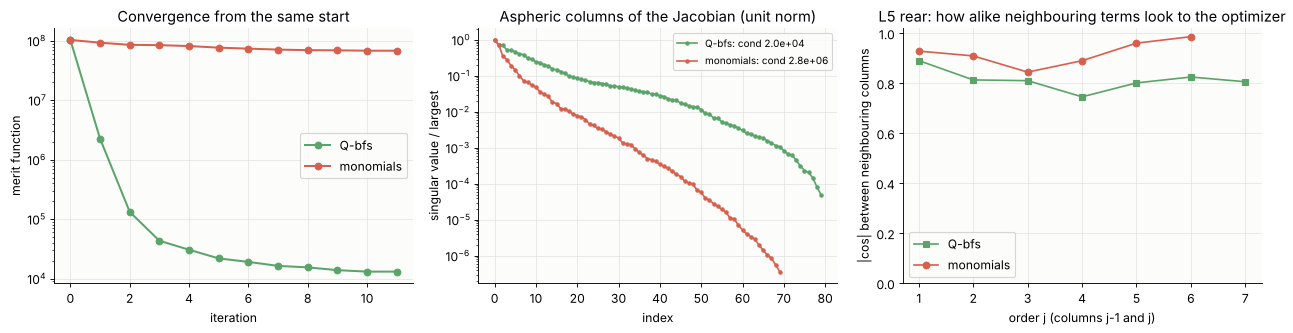

In [6]:
def asphere_block(name):
    # columns of the aspheric variables, each scaled to unit norm
    r = runs[name]
    n0 = len(LENS) + len(common)
    J = np.nan_to_num(r["J0"][:, n0:]*r["opt"]._scale[n0:])
    return J/np.maximum(np.linalg.norm(J, axis=0), 1e-300)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for name, col in (("Q-bfs", GREEN), ("monomials", RED)):
    axes[0].semilogy(runs[name]["history"], "o-", color=col, lw=1.8, label=name)
    sv = np.linalg.svd(asphere_block(name), compute_uv=False)
    axes[1].semilogy(sv/sv[0], ".-", color=col, label="{}: cond {:.1e}".format(name, sv[0]/sv[-1]))
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("merit function")
axes[0].set_title("Convergence from the same start")
axes[0].legend()
axes[1].set_xlabel("index")
axes[1].set_ylabel("singular value / largest")
axes[1].set_title("Aspheric columns of the Jacobian (unit norm)")
axes[1].legend(fontsize=9)
# cosine between neighbouring orders on L5 rear
for name, col, mk in (("Q-bfs", GREEN, "s"), ("monomials", RED, "o")):
    B = asphere_block(name)
    k = 7 if name == "monomials" else 8
    blk = B[:, 9*k:10*k]
    cos = [abs(blk[:, j] @ blk[:, j + 1]) for j in range(k - 1)]
    axes[2].plot(range(1, k), cos, mk + "-", color=col, label=name)
axes[2].set_xlabel("order j (columns j-1 and j)")
axes[2].set_ylabel("|cos| between neighbouring columns")
axes[2].set_title("L5 rear: how alike neighbouring terms look to the optimizer")
axes[2].set_ylim(0, 1.02)
axes[2].legend()
fig.tight_layout()

From the same start (3.8 waves rms on average over the field) the Q-bfs
run brings the merit function down by four orders of magnitude, to
0.07 waves rms on average and 0.16 at worst over 41 fields (better at
infinity than the final design, which also has to be sharp at 100 mm),
while the monomial run creeps along near its start (merit 1.0e8 to
6.8e7 in eleven iterations, 7.5 waves on average). The singular values show
why. The aspheric columns of the Jacobian, each scaled to unit norm, have
a condition number of 2.8e6 with monomials against 2e4 with Q-bfs, and
the cosine between neighbouring monomial orders on L5 rear climbs to
0.98: the optimizer sees seven variables that do nearly the same thing.
The Q-bfs columns are not orthogonal either (their orthogonality is in
the surface slope, not in the wavefront operands; cosines 0.75 to 0.89),
but they never become collinear. Even the final design cannot be written
exactly with seven monomials: the least squares refit misses L5 by
3.6 µm and gives up to 1.2 waves.

**Coefficients.** The monomial design hides its surfaces in coefficients
of alternating sign that cancel each other; the Q coefficients are the
departures themselves:

In [7]:
sm = runs["monomials"]["opt"].system
sq = runs["Q-bfs"]["opt"].system
for i in (8, 9):
    S = sm.surfaces[i]
    print("{} (monomials): R = {:.4f}, K = -1, ".format(NAMES[i], S.R)
          + ", ".join("A{} = {:+.4e}".format(4 + 2*k, a) for k, a in enumerate(S.aspheric)))
    r = NR[i]
    terms = [a*r**(4 + 2*k) for k, a in enumerate(S.aspheric)]
    print("    their sags at r_norm [µm]: " + ", ".join("{:+.1f}".format(t*1e3) for t in terms)
          + "   sum {:+.1f}".format(sum(terms)*1e3))
    print("{} (Q-bfs):     R_bfs = {:.4f}, a = ".format(NAMES[i], sq.surfaces[i].R)
          + ", ".join("{:+.2f}".format(a*1e3) for a in sq.surfaces[i].q) + " µm")
for name in ("Q-bfs", "monomials"):
    s = runs[name]["opt"].system
    print("{:9s}: rms wavefront at 587 nm over the field: {}".format(name, fmt(scan(s))))

L5 front (monomials): R = 2.7731, K = -1, A4 = -5.6723e-01, A6 = +2.8200e-01, A8 = -7.1274e-02, A10 = +9.4007e-03, A12 = -7.1601e-04, A14 = +7.5120e-05, A16 = -6.4718e-06
    their sags at r_norm [µm]: -12904.4, +30600.1, -36888.4, +23206.4, -8430.5, +4218.7, -1733.6   sum -1931.7
L5 front (Q-bfs):     R_bfs = -2.6624, a = -742.27, +241.72, +120.49, +5.03, +13.08, +6.83, +17.37, -9.42, +0.00, +0.00 µm
L5 rear (monomials): R = 1.5444, K = -1, A4 = -1.9104e-01, A6 = +6.4388e-02, A8 = -1.1793e-02, A10 = +1.0492e-03, A12 = -3.6785e-05, A14 = -1.8554e-07, A16 = -8.2560e-09
    their sags at r_norm [µm]: -13122.3, +36653.6, -55637.3, +41026.3, -11920.7, -498.3, -183.8   sum -3682.5
L5 rear (Q-bfs):     R_bfs = -8.4724, a = +2639.15, -362.01, +195.10, +28.86, +80.24, -18.75, +14.08, +5.48, +0.00, +0.00 µm


Q-bfs    : rms wavefront at 587 nm over the field: max 0.156, mean 0.067 waves


monomials: rms wavefront at 587 nm over the field: max 177.669, mean 7.465 waves


## 4. Reading the Q coefficients: the departure spectrum

Each Q-bfs coefficient is, to a good approximation, the rms slope
contribution of its term times $r_\mathrm{norm}$; with the slope
orthonormality the coefficients of one surface add in quadrature to its
rms slope, $\sqrt{\sum a_m^2}/r_\mathrm{norm}$. Plotted as a spectrum per
surface they show at once which surfaces carry the asphericity and how
fast it decays with order:

surface     max departure   rms slope   share of a_0..a_2 in the sum of squares
L1 front          5.3 µm     29.9 mrad    93.6 %
L1 rear           7.9 µm     41.6 mrad    68.7 %
L2 front         25.2 µm     97.5 mrad    99.3 %
L2 rear           8.2 µm     53.7 mrad    96.7 %
L3 front         20.1 µm     50.7 mrad    96.1 %
L3 rear          44.9 µm    118.0 mrad    93.4 %
L4 front         61.1 µm    160.0 mrad    99.0 %
L4 rear         102.6 µm    398.6 mrad    96.6 %
L5 front        156.2 µm    384.8 mrad    95.8 %
L5 rear         470.5 µm    871.5 mrad    99.8 %


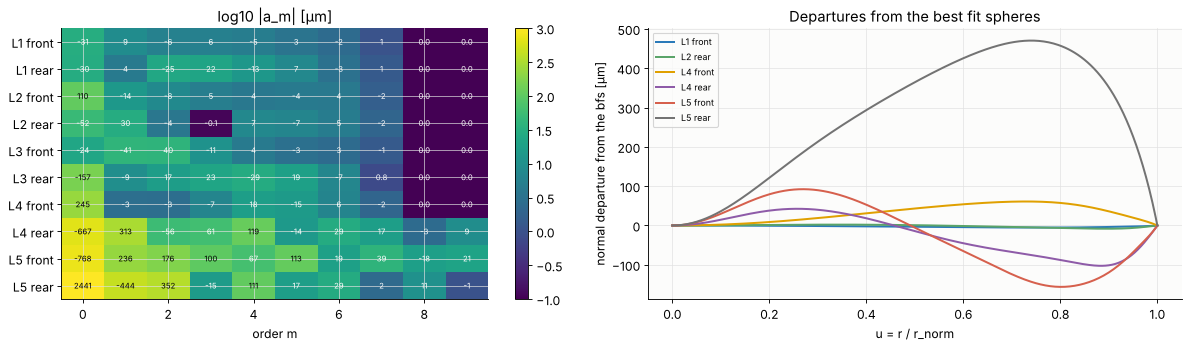

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
NQ = max(len(lens.surfaces[i].q) for i in LENS)
M = np.array([list(lens.surfaces[i].q) + [0.0]*(NQ - len(lens.surfaces[i].q)) for i in LENS])*1e3
im = axes[0].imshow(np.log10(np.abs(M) + 1e-3), cmap="viridis", aspect="auto", vmin=-1, vmax=3)
axes[0].set_yticks(range(10))
axes[0].set_yticklabels(NAMES)
axes[0].set_xlabel("order m")
axes[0].set_title("log10 |a_m| [µm]")
for (i, m), v in np.ndenumerate(M):
    axes[0].text(m, i, "{:.0f}".format(v) if abs(v) >= 1 else "{:.1f}".format(v),
                 ha="center", va="center", fontsize=7, color="w" if abs(v) < 100 else "k")
fig.colorbar(im, ax=axes[0])
for i, col in zip((0, 3, 6, 7, 8, 9), (BLUE, GREEN, ORANGE, PURPLE, RED, GREY)):
    S = lens.surfaces[i]
    r = np.linspace(0, S.norm_radius, 300)
    dep = S.departure(r)*np.sqrt(1 - S.c_bfs**2*r**2)
    axes[1].plot(r/S.norm_radius, dep*1e3, color=col, lw=1.8, label=NAMES[i])
axes[1].set_xlabel("u = r / r_norm")
axes[1].set_ylabel("normal departure from the bfs [µm]")
axes[1].set_title("Departures from the best fit spheres")
axes[1].legend(fontsize=8)
fig.tight_layout()
print("surface     max departure   rms slope   share of a_0..a_2 in the sum of squares")
for i in LENS:
    S = lens.surfaces[i]
    r = np.linspace(0, S.norm_radius, 2001)
    dep = S.departure(r)*np.sqrt(1 - S.c_bfs**2*r**2)
    q = np.array(S.q)
    print("{:9s}   {:9.1f} µm   {:6.1f} mrad   {:5.1f} %".format(
        NAMES[i], np.abs(dep).max()*1e3, S.rms_slope()*1e3, 100*np.sum(q[:3]**2)/np.sum(q**2)))

## 5. Designing for manufacture

The moulds of phone lenses are diamond turned and measured with
profilometers, not interferometers, so the limits are on slope and on
the fine structure that the tool can cut and the mould can fill rather
than on the departure from a sphere. Because the Q-bfs coefficients are
orthonormal in slope, such limits are simple functions of the
coefficients:

- the **rms slope** of a surface is $\sqrt{\sum_m a_m^2}/r_\mathrm{norm}$;
- the **high order content**, $\sqrt{\sum_{m \ge 4} a_m^2}$, measures the
  mid spatial frequency ripple, which costs cutting time, mould filling
  and scattered light.

With monomials neither is a simple function of the coefficients. Here
we cap the high order content of every surface at a value $h$ and
re-optimize, for a few values of $h$, and watch the image quality:

In [9]:
def high_order(i, m0=4):
    def f(system):
        q = np.array(system.surfaces[i].q)
        return np.sqrt(np.sum(q[m0:]**2))
    f.__name__ = "high{}".format(i)
    return f


limits = [None, 50e-3, 20e-3, 5e-3]
tradeoff = []
for h in limits:
    # the same re-optimization at infinity for every limit, also without one
    ops, cons = merit_parts(lens)
    if h is not None:
        cons = cons + [lo.Constraint(high_order(i), upper=h, tolerance=1e-4) for i in LENS]
    V = variables["Q-bfs"]
    opt = lo.DampedLeastSquares(lens, V, ops, constraints=cons, jac="analytic")
    opt.run(max_iterations=6)
    tradeoff.append((h, opt.system, scan(opt.system)))
    print("{:14s}: rms wavefront {}".format(
        "no limit" if h is None else "h = {:4.1f} µm".format(h*1e3), fmt(tradeoff[-1][2])))

no limit      : rms wavefront max 0.162, mean 0.091 waves


h = 50.0 µm   : rms wavefront max 0.284, mean 0.161 waves


h = 20.0 µm   : rms wavefront max 0.592, mean 0.257 waves


h =  5.0 µm   : rms wavefront max 0.619, mean 0.308 waves


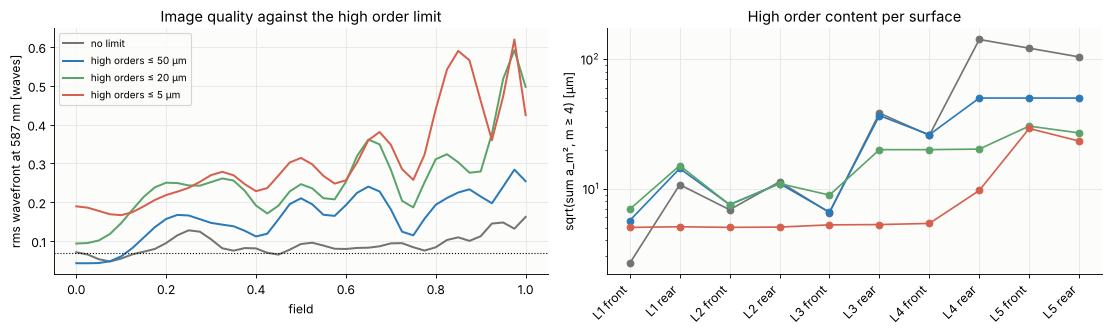

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for (h, s, w), col in zip(tradeoff, (GREY, BLUE, GREEN, RED)):
    lab = "no limit" if h is None else "high orders ≤ {:.0f} µm".format(h*1e3)
    axes[0].plot(SCAN, w, "-", color=col, lw=1.8, label=lab)
    hi = [np.sqrt(np.sum(np.array(s.surfaces[i].q[4:])**2))*1e3 for i in LENS]
    axes[1].semilogy(range(10), np.maximum(hi, 1e-3), "o-", color=col, label=lab)
axes[0].axhline(0.07, color="k", ls=":", lw=1)
axes[0].set_xlabel("field")
axes[0].set_ylabel("rms wavefront at 587 nm [waves]")
axes[0].set_title("Image quality against the high order limit")
axes[0].legend(fontsize=9)
axes[1].set_xticks(range(10))
axes[1].set_xticklabels(NAMES, rotation=45, ha="right")
axes[1].set_ylabel("sqrt(sum a_m², m ≥ 4) [µm]")
axes[1].set_title("High order content per surface")
fig.tight_layout()

Capping the high order content is an explicit trade, and here an
expensive one: L4 rear and L5 front carry 120 to 140 µm each in their terms from
$a_4$ on. Re-optimized the same way at infinity (six iterations each),
the lens reaches 0.09 waves rms on average over the field and 0.16 at
worst without a limit, 0.16 and 0.28 with a cap of 50 µm, and 0.26 and
0.59 with 20 µm; at 5 µm (0.31 and 0.62) it is no better, and the
optimizer has run out of freedom. Since the cap is a
quadratic function of the coefficients, it went into the optimizer as an
ordinary constraint; with monomials it would need the surface to be
sampled.

## 6. Truncation

Orthogonality has a second practical consequence: dropping the highest
terms changes the surface by exactly those terms, which are the smallest
ones. With monomials the terms are only meaningful together, so dropping
the highest one leaves its large partners uncompensated. We truncate both
final designs of section 3 to their first $k$ aspheric terms (no
re-optimization, but refocused) and compare the rms wavefront on axis and
at 0.7 field:

Q-bfs, 3 terms: 1.106 / 1.756 waves
Q-bfs, 4 terms: 2.289 / 1.752 waves
Q-bfs, 5 terms: 2.487 / 1.375 waves
Q-bfs, 6 terms: 0.486 / 0.726 waves
Q-bfs, 7 terms: 0.078 / 0.557 waves
Q-bfs, 8 terms: 0.020 / 0.079 waves
monomials, 2 terms: nan / nan waves
monomials, 3 terms: nan / nan waves
monomials, 4 terms: nan / nan waves
monomials, 5 terms: 3.907 / 9.869 waves
monomials, 6 terms: 25.529 / 130.900 waves
monomials, 7 terms: 4.639 / 1.199 waves


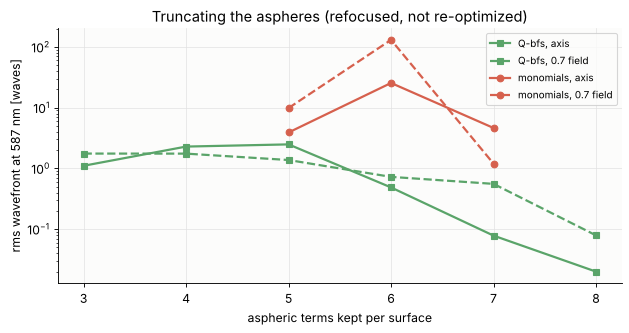

In [11]:
def truncate_mono(system, n_keep):
    s = system.copy()
    for i in LENS:
        A = list(s.surfaces[i].aspheric)
        s.surfaces[i].aspheric = tuple(A[:n_keep] + [0.0]*(len(A) - n_keep))
    return s


def refocused_rms(system):
    # best image distance for the field average, then the rms at 0.7 field and on axis
    best = None
    for dz in np.linspace(-0.02, 0.02, 9):
        s = system.copy()
        s.surfaces[-1].thickness += dz
        with np.errstate(all="ignore"):
            w = np.array([s.rms_opd(f*full) for f in (0, .7)])
        if np.all(np.isfinite(w)) and (best is None or w.mean() < best.mean()):
            best = w
    return np.full(2, np.nan) if best is None else best


kq = list(range(3, 9))
km = list(range(2, 8))
tq = [refocused_rms(truncated(sq, k)) for k in kq]
tm = [refocused_rms(truncate_mono(sm, k)) for k in km]
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.semilogy(kq, [t[0] for t in tq], "s-", color=GREEN, lw=2, label="Q-bfs, axis")
ax.semilogy(kq, [t[1] for t in tq], "s--", color=GREEN, lw=2, label="Q-bfs, 0.7 field")
ax.semilogy(km, [t[0] for t in tm], "o-", color=RED, lw=2, label="monomials, axis")
ax.semilogy(km, [t[1] for t in tm], "o--", color=RED, lw=2, label="monomials, 0.7 field")
ax.set_xlabel("aspheric terms kept per surface")
ax.set_ylabel("rms wavefront at 587 nm [waves]")
ax.set_title("Truncating the aspheres (refocused, not re-optimized)")
ax.legend(fontsize=9)
fig.tight_layout()
for k, t in zip(kq, tq):
    print("Q-bfs, {} terms: {:.3f} / {:.3f} waves".format(k, *t))
for k, t in zip(km, tm):
    print("monomials, {} terms: {:.3f} / {:.3f} waves".format(k, *t))

The truncated Q-bfs lens stays a lens: every truncation traces, and the
error falls from 1 to 2 waves with three terms to 0.02 (axis) and 0.08
(0.7 field) with all eight, though not monotonically (the fourth and
fifth terms alone make the axis worse; they are balanced by the sixth).
Truncated monomials are a different story: with two to four terms rays
miss the surfaces altogether (no number at all, the NaN), and five to
seven terms give 1.2 to 130 waves. Note that the monomial design is the stalled one of section 3,
which is why its full set is not as good as the Q-bfs lens either.

## 7. Final results: Zernike wavefronts over the sensor

The wavefront of the final design as Fringe Zernike coefficients (in
waves, over the entrance pupil; $Z_4$ defocus, $Z_5, Z_6$ astigmatism,
$Z_7, Z_8$ coma, $Z_9$ spherical aberration, then the higher orders),
mapped over a 4:3 sensor whose diagonal is the full field, 13 × 9 field
points, with the image plane fixed where the optimization put it. At
infinity a field point is a pair of angles, the direction
$(\tan\theta_x, \tan\theta_y, 1)$, so the grid is laid out in
$\tan\theta$ to be even on the sensor; at 100 mm it is a pair of object
heights.

A phone camera lens has one focal length, so there are no zoom
positions; it focuses by moving the whole lens with a voice coil motor.
Close focus is the second configuration: the object at 100 mm, the lens
moved away from the sensor so that the field is in focus again
(`pl.close_focus()`; the lens itself unchanged).

In [12]:
from pyoptics import bases

# the sensor (4:3, half diagonal = image height) as a grid of field points; at infinity the field
# pair is (field angle in x, field angle in y), i.e. the direction (tan fx, tan fy, 1)
near, dz = pl.close_focus(lens)
print("lens moved by {:.3f} mm for 100 mm (paraxial estimate f²/(s - f) = {:.3f} mm)".format(
    dz, pl.EFL**2/(pl.CLOSE_DISTANCE - pl.EFL)))
H = pl.EFL*np.tan(full)                                    # half diagonal of the sensor [mm]
U, V = np.linspace(-0.8, 0.8, 13), np.linspace(-0.6, 0.6, 9)   # fractions of the half diagonal
UV = np.array([(u, v) for v in V for u in U])
FIELD_GRID = {"infinity": np.arctan(UV*np.tan(full)), "100 mm": UV*near.max_field}
CASES = {"infinity": lens, "100 mm": near}


def wavefront(system, field, n_terms=16, N=48, cut=5.0):
    """Fringe Zernikes and rms (tilt removed) [waves] of the OPD map, without
    the few rays at the rim of the pupil that are close to total internal
    reflection (more than cut waves from the median; see the text)"""
    m = system.opd(field, N)
    PX, PY = np.meshgrid(m.px, m.py)
    ok = np.isfinite(m.W)
    ok &= np.abs(m.W - np.median(m.W[ok])) < cut
    W, x, y = m.W[ok], PX[ok], PY[ok]
    A = np.column_stack([bases.fringe_zernike(j, x, y) for j in range(1, n_terms + 1)])
    z = np.linalg.lstsq(A, W, rcond=None)[0]
    r = W - A[:, :3] @ np.linalg.lstsq(A[:, :3], W, rcond=None)[0]
    return z, np.sqrt(np.mean(r**2)), np.sum(np.isfinite(m.W)) - ok.sum()


ZMAP, RMSMAP, DROPPED = {}, {}, {}
for name, s in CASES.items():
    for wl in WLS:
        sw = s.copy()
        sw.wavelength = wl
        res = [wavefront(sw, tuple(f)) for f in FIELD_GRID[name]]
        if wl == WLS[1]:
            ZMAP[name] = np.array([z for z, _, _ in res])
        RMSMAP[name, wl] = np.array([r for _, r, _ in res])
        DROPPED[name, wl] = sum(k for _, _, k in res)
print("rays left out (of 1716 per field and {} fields): ".format(len(UV))
      + ", ".join("{} at {:.0f} nm: {}".format(n, wl*1e6, k) for (n, wl), k in DROPPED.items()))
EXT = [H*(U[0] - 0.067), H*(U[-1] + 0.067), H*(V[0] - 0.075), H*(V[-1] + 0.075)]


def zmap(ax, m, title, cmap="RdBu_r", vmax=None, symmetric=True):
    m = m.reshape(len(V), len(U))
    a = vmax if vmax is not None else np.nanmax(np.abs(m))
    im = ax.imshow(m, extent=EXT, origin="lower", cmap=cmap,
                   vmin=-a if symmetric else 0, vmax=a, interpolation="bicubic")
    ax.set_title(title, fontsize=10)
    ax.grid(False)
    return im


TERMS = [(4, "defocus"), (5, "astigmatism 0°"), (6, "astigmatism 45°"), (7, "coma x"),
         (8, "coma y"), (9, "spherical"), (10, "trefoil 30°"), (11, "trefoil 0°"),
         (12, "2nd astigmatism 0°"), (16, "2nd spherical")]

lens moved by 0.165 mm for 100 mm (paraxial estimate f²/(s - f) = 0.167 mm)


rays left out (of 1716 per field and 117 fields): infinity at 486 nm: 0, infinity at 588 nm: 0, infinity at 656 nm: 0, 100 mm at 486 nm: 0, 100 mm at 588 nm: 1, 100 mm at 656 nm: 0


The maps are over the nominal image position $f \tan\theta$. The lens is
rotationally symmetric, so every map is a radial profile turned with
the azimuth $\varphi$ of the field point the way its Zernike demands:
$Z_4$, $Z_9$ and $Z_{16}$ are rings; the astigmatism pair $Z_5, Z_6$
turns twice per circle ($\cos 2\varphi$, $\sin 2\varphi$), coma $Z_7,
Z_8$ once and trefoil $Z_{10}, Z_{11}$ three times. A coefficient at one
field point on the $y$ axis (the usual lens design convention) tells the
whole story only together with this rule, which is why tables over $y$
and maps over the sensor show the same lens. The terms swing in sign
several times from the centre to the corner, the signature of the wavy
L4 and L5.

To compute the maps, a handful of rays per sensor (one of 1716 at one
corner at 100 mm, 588 nm) were left out: at the very rim of the pupil
the edge rays of the corner field come close to total internal
reflection at L4 rear and leave it at grazing angles, with hundreds of
waves of path error. They pass outside the clear aperture of the later
surfaces, where a real module has the flange and the barrel to block
them.

The rms wavefront over the sensor at the three wavelengths:

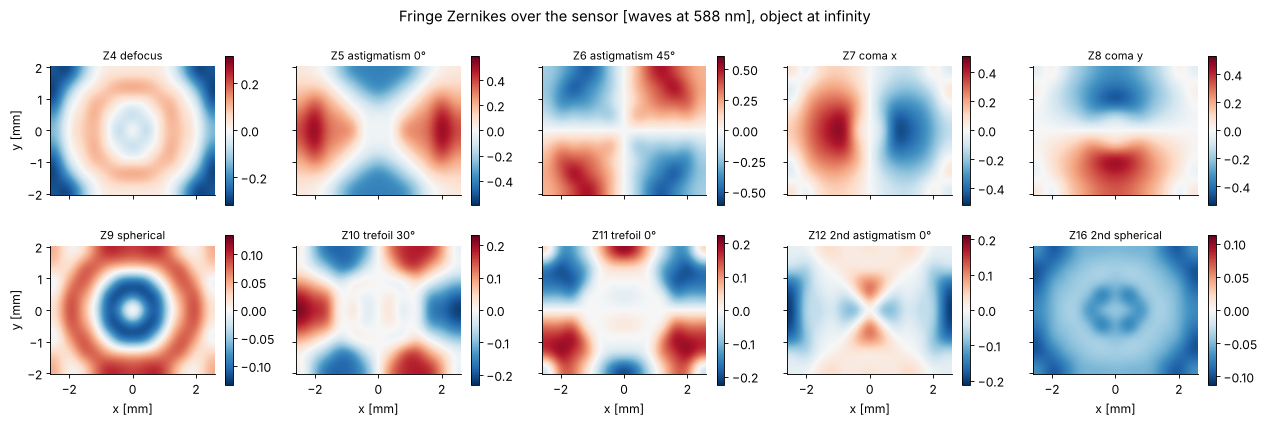

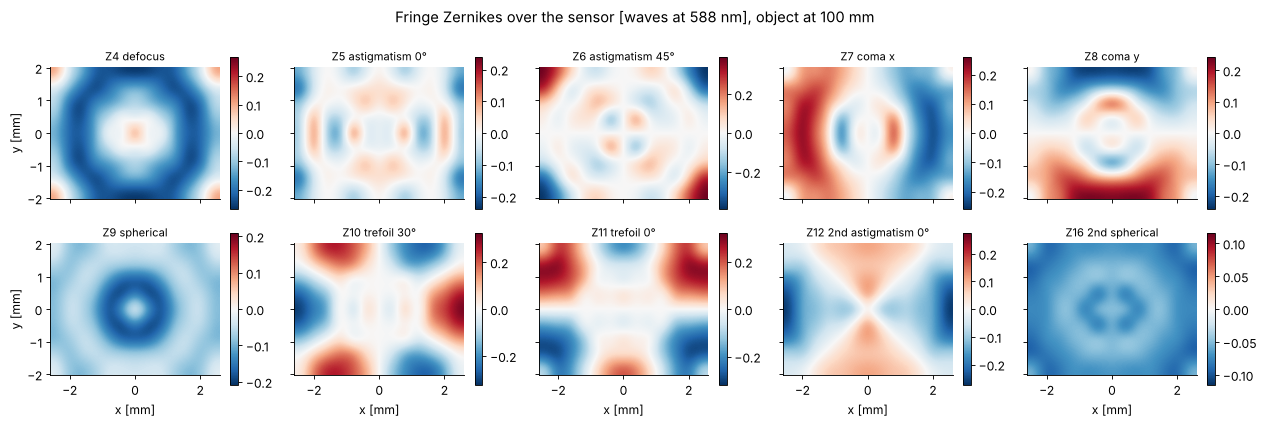

In [13]:
for name in CASES:
    fig, axes = plt.subplots(2, 5, figsize=(16, 5.4), sharex=True, sharey=True)
    for ax, (j, lab) in zip(axes.ravel(), TERMS):
        im = zmap(ax, ZMAP[name][:, j - 1], "Z{} {}".format(j, lab))
        fig.colorbar(im, ax=ax, shrink=0.85)
    for ax in axes[1]:
        ax.set_xlabel("x [mm]")
    for ax in axes[:, 0]:
        ax.set_ylabel("y [mm]")
    fig.suptitle("Fringe Zernikes over the sensor [waves at 588 nm], object at " + name)
    fig.tight_layout()

At infinity the lens is 0.10 to 0.36 waves rms over the whole sensor
and all three wavelengths, best in the centre; at 100 mm 0.09 to 0.51,
where the blue corners are the weakest part of the design (the longitudinal
colour changes with the object distance and the image plane is a
compromise for both). The same astigmatism and coma as a full-field
display (notebook 155, off-axis mirrors and nodal aberrations): a line
along the axis of the astigmatism, an arrow in the direction of the coma,
both with lengths to the same scale at both distances:

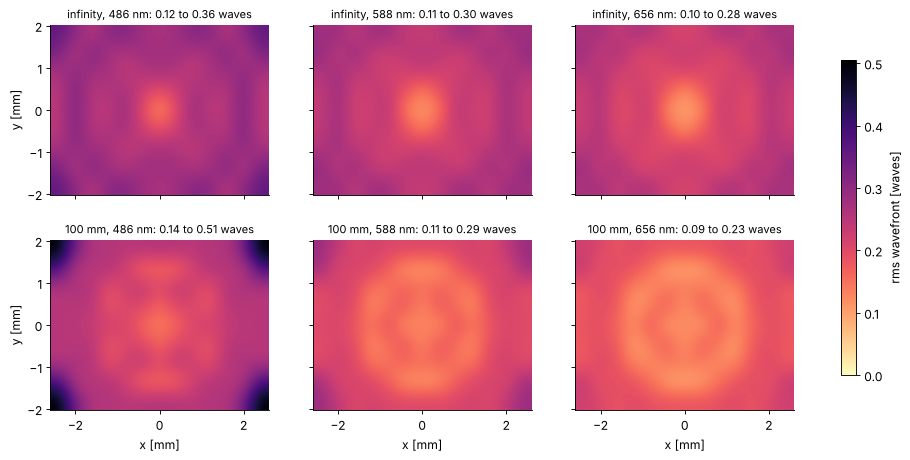

In [14]:
vmax = max(np.nanmax(RMSMAP[k]) for k in RMSMAP)
fig, axes = plt.subplots(2, 3, figsize=(15, 6.4), sharex=True, sharey=True)
for row, name in enumerate(CASES):
    for col, wl in enumerate(WLS):
        r = RMSMAP[name, wl]
        im = zmap(axes[row, col], r, "{}, {:.0f} nm: {:.2f} to {:.2f} waves".format(
            name, wl*1e6, np.nanmin(r), np.nanmax(r)), cmap="magma_r", vmax=vmax, symmetric=False)
for ax in axes[1]:
    ax.set_xlabel("x [mm]")
for ax in axes[:, 0]:
    ax.set_ylabel("y [mm]")
fig.colorbar(im, ax=axes, shrink=0.8, label="rms wavefront [waves]")

Both displays have the symmetry of a centred system: the astigmatism
lines are radial or tangential, depending on its sign, and the coma
arrows point towards or away from the centre. At 100 mm the astigmatism
is smaller than at infinity over most of the sensor and grows only in the
corners.

Last, the reason for the 21 fields of the merit function: radial scans
of the rms wavefront with 41 fields, for the final design at the three
wavelengths and for the earlier design that was optimized at infinity
only, at the six fields marked orange:

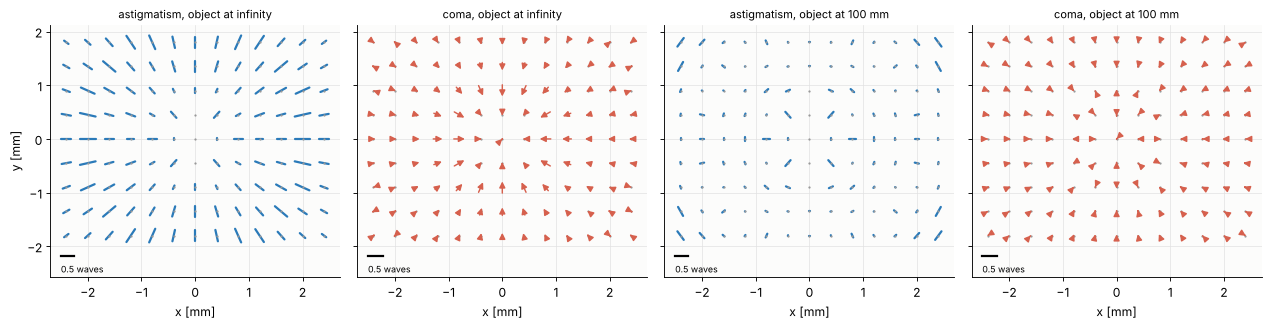

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9), sharey=True)
pts = UV*H
sc_a = 0.3/max(np.abs(ZMAP[n][:, 4] + 1j*ZMAP[n][:, 5]).max() for n in CASES)
sc_c = 0.3/max(np.abs(ZMAP[n][:, 6] + 1j*ZMAP[n][:, 7]).max() for n in CASES)
for k, name in enumerate(CASES):
    Z = ZMAP[name]
    oa.plot_full_field(axes[2*k], pts, Z[:, 4] + 1j*Z[:, 5], "astigmatism", scale=sc_a, color=BLUE, lw=2)
    oa.plot_full_field(axes[2*k + 1], pts, Z[:, 6] + 1j*Z[:, 7], "coma", scale=sc_c, color=RED, lw=1.3)
    axes[2*k].set_title("astigmatism, object at " + name, fontsize=10)
    axes[2*k + 1].set_title("coma, object at " + name, fontsize=10)
for ax, sc in zip(axes, (sc_a, sc_c, sc_a, sc_c)):
    ax.plot([EXT[0] + 0.1, EXT[0] + 0.1 + 0.5*sc], [EXT[2] - 0.15]*2, color="k", lw=2)
    ax.text(EXT[0] + 0.1, EXT[2] - 0.3, "0.5 waves", fontsize=8, va="top")
    ax.set_xlim(EXT[0] - 0.1, EXT[1] + 0.1)
    ax.set_ylim(EXT[2] - 0.55, EXT[3] + 0.1)
    ax.set_xlabel("x [mm]")
axes[0].set_ylabel("y [mm]")
fig.tight_layout()

The lens moved 0.165 mm to focus at 100 mm, close to the paraxial
$f^2/(s-f) = 0.167$ mm. The earlier design looks acceptable at the six
fields it was optimized at, and is up to 0.9 waves at infinity and
1.6 waves at 100 mm between them: the optimizer had used the freedom of
the wavy surfaces to put the aberration where nobody looked. An
intermediate version of the final design, polished for both distances
but still at six fields, had the same holes (1.0 and 1.7 waves). With
21 fields the final design varies smoothly over the field, 0.09 to 0.30
waves at 588 nm at infinity and 0.09 to 0.31 at 100 mm, and checking it
with a field scan twice as dense, or with the maps above, shows no
hidden holes.

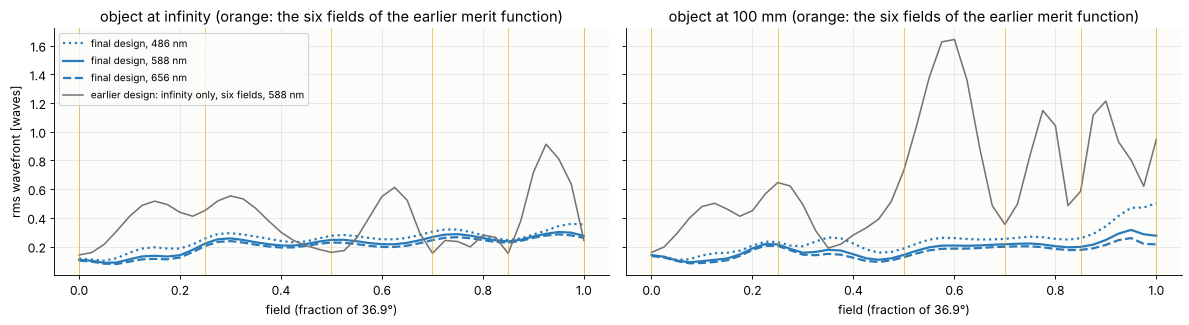

In [16]:
# radial scans with 41 fields against the six fields the earlier merit function sampled
SCAN = np.linspace(0, 1, 41)
old = pl.phone_lens(pl.DESIGN_INFINITY)
old_near, old_dz = pl.close_focus(old)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=True)
for ax, pair, title in ((axes[0], (lens, old), "object at infinity"), (axes[1], (near, old_near), "object at 100 mm")):
    new_s, old_s = pair
    for wl, ls in zip(WLS, (":", "-", "--")):
        sw = new_s.copy()
        sw.wavelength = wl
        ax.plot(SCAN, [sw.rms_opd(f*sw.max_field, N=48) for f in SCAN], ls, color=BLUE, lw=2,
                label="final design, {:.0f} nm".format(wl*1e6))
    ax.plot(SCAN, [old_s.rms_opd(f*old_s.max_field, N=48) for f in SCAN], "-", color=GREY, lw=1.4,
            label="earlier design: infinity only, six fields, 588 nm")
    for f in (0, .25, .5, .7, .85, 1.0):
        ax.axvline(f, color=ORANGE, lw=0.8, alpha=0.6)
    ax.set_xlabel("field (fraction of 36.9°)")
    ax.set_title(title + " (orange: the six fields of the earlier merit function)")
axes[0].set_ylabel("rms wavefront [waves]")
axes[0].legend(fontsize=9)
fig.tight_layout()

**How good is it?** By Maréchal's criterion (0.07 waves rms, a Strehl
ratio of 0.8) the lens is diffraction limited only on axis; over the
field it is three to four times that. Published phone lenses are
better: re-optimized patent designs with six and seven elements at f/2
and 33° half field reach 0.013 to 0.033 waves rms over the field (Nie
2017), and Steinich and Blahnik (2012) describe phone lenses as close
to the diffraction limit by necessity, with MTF specifications of 40 %
on axis and 30 % at 80 % field at half the Nyquist frequency (180 lp/mm
for 1.4 µm pixels) at f/2.8. Tolerancing then eats a large part of the
margin: in Monte Carlo runs on the six element lens the rms grows by a
factor 1.4 to 3.8, and 0.5 waves rms as built is a common pass mark
(Jian 2020). Our lens has one element less, is faster (f/1.8) and wider
(36.9°), and is held to 100 mm close focus, but it started from
spheres and settled into its form at 40 % field (section 2); with
another element, or a global search, it would have room to improve.

## 8. Coda: Q2D freeform terms on a tilted mirror

Q-bfs is rotationally symmetric. Forbes extended it to freeforms (Q2D,
2012): the same best fit sphere and normal departure, with terms
$u^m Q_n^m(u^2)\cos m\varphi$ and $\sin m\varphi$ whose gradients are
orthonormal in the same weight, so the coefficients still add up to the
rms slope. A natural use next to a phone camera is the folded telephoto
("periscope") module, where a mirror or prism bends the beam by 90° and
there is room for freeform power in the fold.

A minimal example in the spirit of
notebook 155 (off-axis mirrors and nodal aberrations): a concave mirror, f = 30 mm at f/4, tilted by 12°,
over a ±1.5° field. The tilt brings astigmatism on axis. With
`qaspheres.Q2DSurface` and a few low order coefficients of $m = 0 \dots 3$
(but not the $m = 1$, $n = 0$ term, a pure tilt that would only re-aim
the mirror) as variables:

In [17]:
A_TILT = np.radians(12.0)
R_M, RN_M = -60.0, 4.0


def folded(cos=None, sin=None):
    S = [rt.Surface(np.inf, 20.0, semi_diameter=3.75),
         rt.CoordinateBreak(tilt=(A_TILT, 0, 0)),
         qa.Q2DSurface(R_M, 0.0, cos=cos, sin=sin, norm_radius=RN_M, mirror=True),
         rt.CoordinateBreak(tilt=(A_TILT, 0, 0), thickness=R_M/2)]
    return rt.System(S, 0, WLS[1], field_angle=np.radians(1.5))


F = np.radians(1.5)
fields2d = np.array([(0, 0), (F, 0), (-F, 0), (0, F), (0, -F), (F, F), (-F, -F), (F, -F), (-F, F)])
terms = [(0, 0, "cos"), (0, 1, "cos"), (1, 1, "cos"), (1, 1, "sin"), (1, 2, "sin"), (2, 0, "cos"),
         (2, 0, "sin"), (2, 1, "cos"), (2, 1, "sin"), (3, 0, "cos"), (3, 0, "sin"), (3, 1, "sin"),
         (4, 0, "cos")]
mirror0 = folded()
V = [qa.Q2DCoefficient(2, m, n, k) for m, n, k in terms] + [lo.Thickness(3)]
designs = {}
for name, fl in (("axis", fields2d[:1]), ("field", fields2d)):
    opt = lo.DampedLeastSquares(mirror0, V, [oa.field_wavefront(fl, rings=(0.5, 0.85, 1.0),
                                                                spokes=8, tolerance=0.02)])
    opt.run(max_iterations=40)
    designs[name] = opt.system
mirror1 = designs["axis"]
labels = ["axis", "+x", "-x", "+y", "-y", "+x+y", "-x-y", "+x-y", "-x+y"]
print("rms wavefront [waves]")
print("field     sphere    Q2D, optimized on axis    Q2D, optimized over the field")
for f, lab in zip(fields2d, labels):
    print("{:6s}    {:6.3f}    {:6.3f}                    {:6.3f}".format(
        lab, mirror0.rms_opd(tuple(f)), designs["axis"].rms_opd(tuple(f)), designs["field"].rms_opd(tuple(f))))
M1 = mirror1.surfaces[2]
print("Q2D coefficients of the on-axis design [µm]: " + ", ".join(
    "{}{}{}: {:+.2f}".format("a" if k == "cos" else "b", m, n, M1.get_term(k, m, n)*1e3)
    for m, n, k in terms if abs(M1.get_term(k, m, n)) > 1e-6)
    + "; rms slope {:.2f} mrad".format(M1.rms_slope()*1e3))

rms wavefront [waves]
field     sphere    Q2D, optimized on axis    Q2D, optimized over the field
axis       3.629     0.000                     0.243
+x         3.652     0.904                     0.793
-x         3.652     0.904                     0.793


+y         4.224     0.919                     0.889
-y         3.122     0.874                     0.790
+x+y       4.247     1.304                     1.177
-x-y       3.146     1.240                     1.066
+x-y       3.146     1.240                     1.066


-x+y       4.247     1.304                     1.177
Q2D coefficients of the on-axis design [µm]: a00: -0.13, b11: -1.71, b12: -0.00, a20: -4.16, a21: -0.01, b30: -0.04; rms slope 1.12 mrad


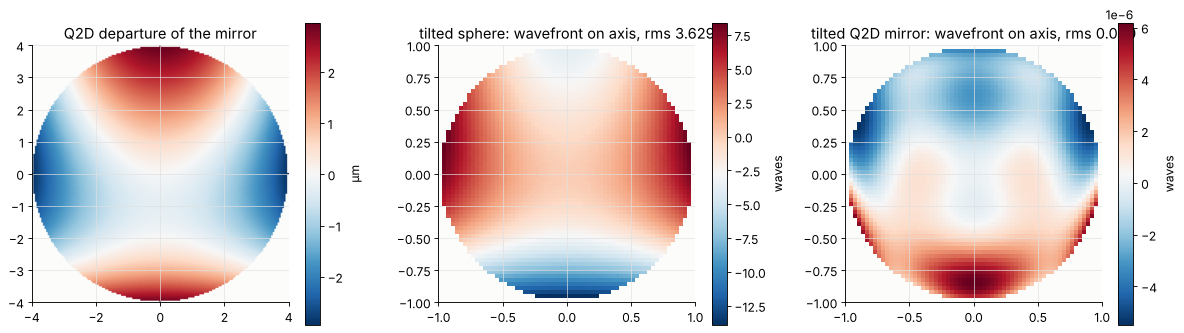

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
x = np.linspace(-RN_M, RN_M, 161)
X, Y = np.meshgrid(x, x)
inside = X**2 + Y**2 <= RN_M**2
D = np.where(inside, M1.departure(X, Y), np.nan)*1e3
im = axes[0].imshow(D, extent=[-RN_M, RN_M, -RN_M, RN_M], origin="lower", cmap="RdBu_r")
fig.colorbar(im, ax=axes[0], label="µm")
axes[0].set_title("Q2D departure of the mirror")
for ax, s, title in ((axes[1], mirror0, "tilted sphere"), (axes[2], mirror1, "tilted Q2D mirror")):
    W = s.opd((0.0, 0.0), N=64).W
    im = ax.imshow(W, extent=[-1, 1, -1, 1], origin="lower", cmap="RdBu_r")
    fig.colorbar(im, ax=ax, label="waves")
    ax.set_title("{}: wavefront on axis, rms {:.3f}".format(title, s.rms_opd((0.0, 0.0))))
fig.tight_layout()

Optimized on axis, the $m = 2$ term ($a_{20} = -4.2$ µm) takes out the
astigmatism of the tilt and the $m = 1$ coma term ($b_{11} = -1.7$ µm) the
coma, and the axis is perfect, with only 1.1 mrad rms slope of freeform
departure. Over the field the single surface cannot hold that: the edge
keeps 0.9–1.3 waves, about a quarter of the sphere, and balancing the
field costs 0.24 waves on axis for only 10 % gain at the edge. What
remains is the field dependence of a single surface
(notebook 155, off-axis mirrors and nodal aberrations), which a second freeform would address.

## Summary

- A five element f/1.8 phone lens with a 37° half field (f = 4 mm,
  5.26 mm total track) was designed from rough spherical radii with Q-bfs
  surfaces throughout, by widening the field in small steps; the chief
  ray angle limit had to grow with the field from early on. Polished for
  infinity and 100 mm together, it reaches 0.10 to 0.36 waves rms at
  486 to 656 nm over the whole sensor at infinity and 0.09 to 0.51 at
  100 mm: diffraction limited on axis only, and about ten times the
  nominal error of published six and seven element designs.
- The merit function is only as good as its sampling: four hand-picked
  pupil rings, rings short of the rim, an unsampled field and six fields
  with up to 1.7 waves between them each let the optimizer hide
  aberration, and a gap that was not sampled across the aperture let L5
  cut into the filter. The wavy aspheres need a dense field sampling
  (here 21 fields), checked by a scan twice as dense.
- From the same start, the Q-bfs parameterization converges (merit 1.0e8
  to 1.3e4) where monomials creep along near the start, with nearly
  collinear neighbouring orders on the wavy rear surface. Seven monomials
  cannot even represent the final design to better than 3.6 µm.
- The Q coefficients form a readable departure spectrum: the asphericity
  is concentrated on L4 and L5, and 65 to 100 % of it is in the first three
  orders.
- Manufacturing limits such as the rms slope or the high order content
  are simple quadratic functions of the Q coefficients and can be put on
  the optimizer directly; here a cap of 50 µm on the high orders costs
  a factor of 1.8 in wavefront error, 20 µm a factor of 3 to 4.
- A truncated Q-bfs lens still traces and improves overall as terms are
  added (not monotonically); truncated monomials lose rays or give tens of
  waves.
- The final wavefront is mapped as Fringe Zernikes over the sensor, at
  486, 588 and 656 nm for infinity and 100 mm, with full-field displays
  of astigmatism and coma.
- Q2D terms extend the description to freeforms; on a tilted mirror they
  remove the aberrations of the tilt on axis, and a single surface leaves
  about a quarter of the spherical mirror's error at the edge of the field.

## References

- G. W. Forbes, "Shape specification for axially symmetric optical
  surfaces", Opt. Express 15, 5218–5226 (2007).
- G. W. Forbes, "Manufacturability estimates for optical aspheres",
  Opt. Express 19, 9923–9941 (2011).
- G. W. Forbes, "Characterizing the shape of freeform optics", Opt.
  Express 20, 2483–2499 (2012).
- J. Sasián, "Introduction to Lens Design", Cambridge University Press
  (2019), on phone camera lenses.
- L. Nie, "Patent review of miniature camera lenses and a brief
  comparison of two relative design patterns", M.S. report, University of
  Arizona (2017).
- H.-M. Jian, "Study of tolerance analysis for mobile phone lenses", M.S.
  thesis, University of Arizona (2020).
- T. Steinich and V. Blahnik, "Optical design of camera optics for mobile
  phones", Adv. Opt. Technol. 1, 51–58 (2012).

In [19]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 1422 s
